# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "run.py").exists():
    os.chdir(Path.cwd().parent)

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, weekly data, 0% risk-free) ---
    weekly_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(weekly_returns) > 0:
        sharpe = (np.mean(weekly_returns) / np.std(weekly_returns)) * np.sqrt(52)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))


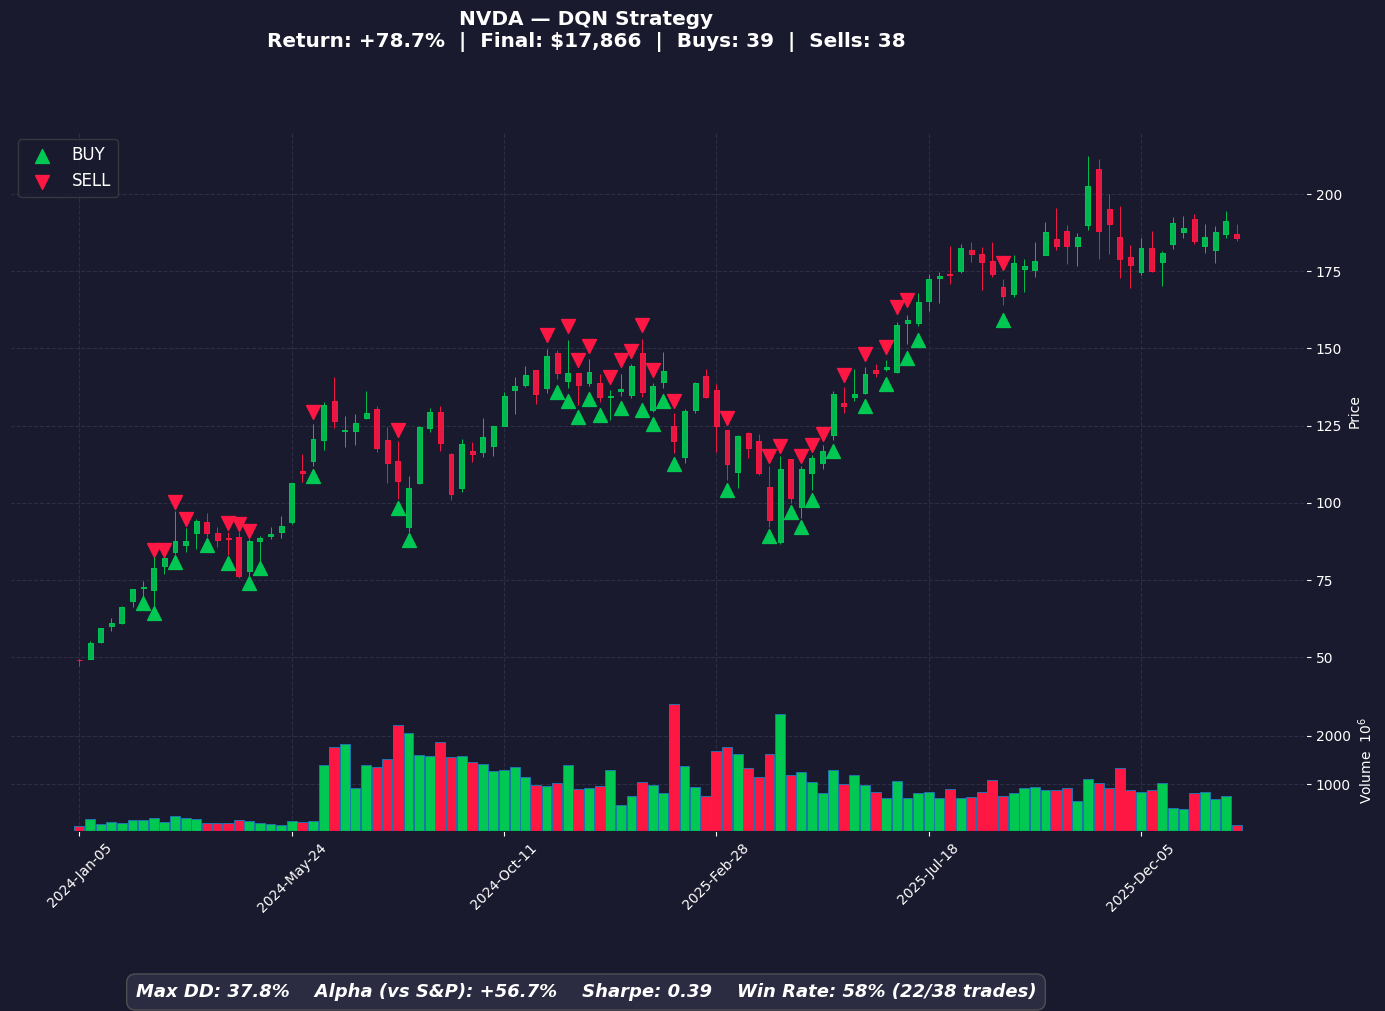

### NVDA — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$73.86,135,"$9,971.02","$9,990.03"
2024-02-23,SELL,$78.77,135,"$10,634.45","$10,642.82"
2024-02-26,BUY,$79.05,134,"$10,592.51","$10,632.23"
2024-03-04,SELL,$85.19,134,"$11,415.48","$11,443.79"
2024-03-07,BUY,$92.62,123,"$11,392.56","$11,432.40"
2024-03-08,SELL,$87.48,123,"$10,760.53","$10,789.62"
2024-03-11,BUY,$85.73,125,"$10,716.36","$10,778.90"
2024-03-13,SELL,$90.84,125,"$11,355.29","$11,406.47"
2024-03-27,BUY,$90.20,126,"$11,365.78","$11,395.11"
2024-04-12,SELL,$88.14,126,"$11,105.85","$11,124.07"


In [2]:
plot_ticker('NVDA', method='DQN')

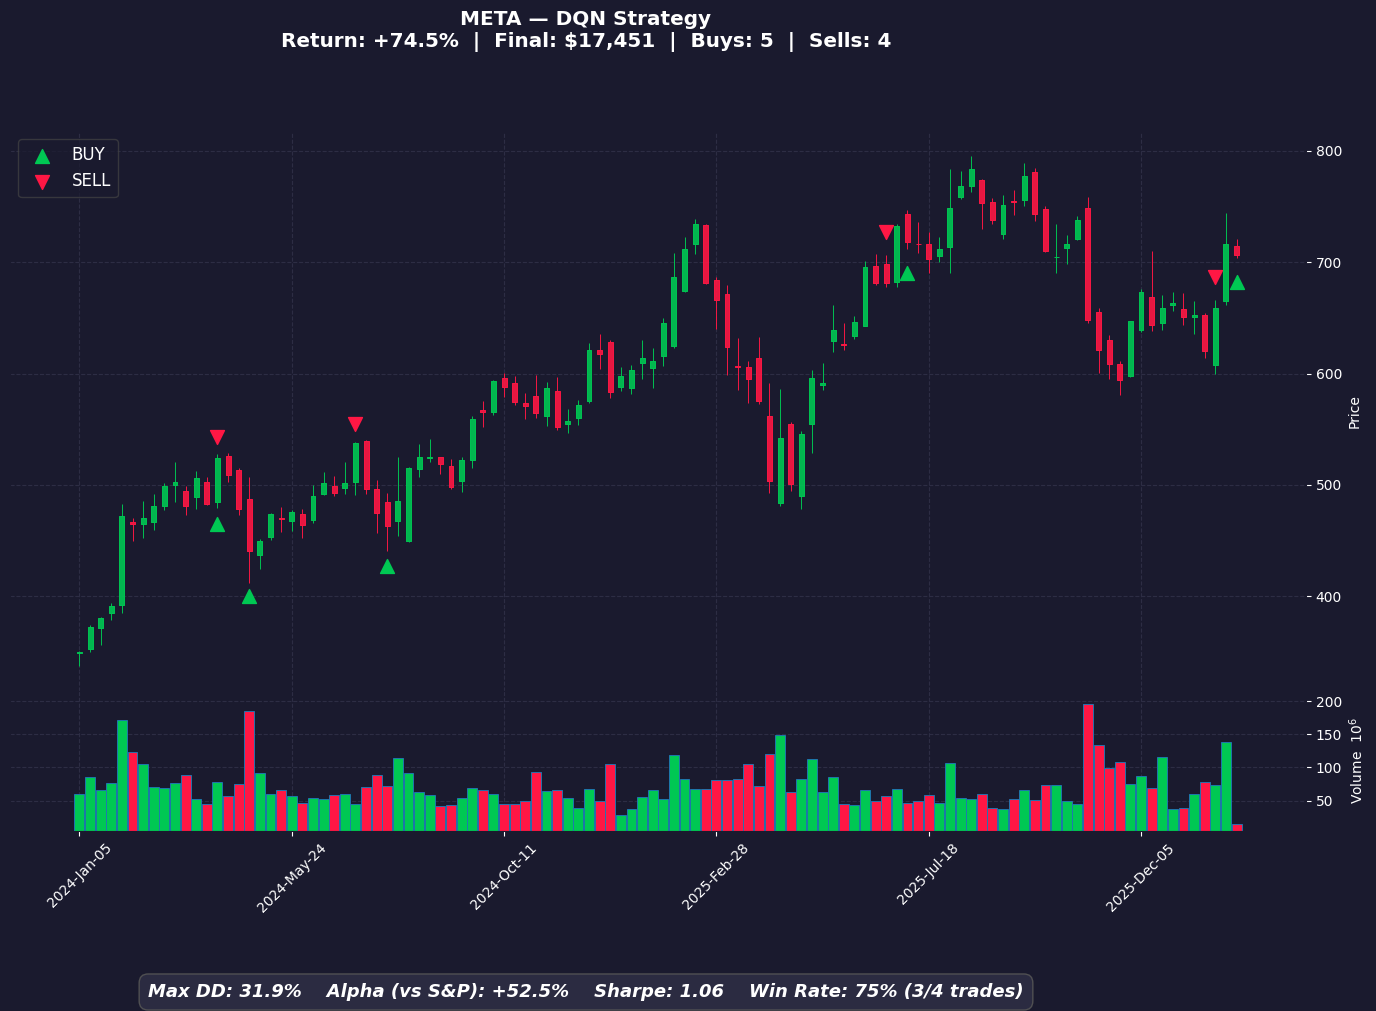

### META — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-01,BUY,$488.49,20,"$9,769.81","$9,990.23"
2024-04-08,SELL,$516.23,20,"$10,324.56","$10,534.66"
2024-04-29,BUY,$430.10,24,"$10,322.46","$10,524.34"
2024-07-08,SELL,$526.76,24,"$12,642.28","$12,831.51"
2024-07-29,BUY,$463.46,27,"$12,513.39","$12,819.00"
2025-06-23,SELL,$697.49,27,"$18,832.11","$19,118.89"
2025-06-30,BUY,$736.99,25,"$18,424.66","$19,100.46"
2026-01-26,SELL,$672.36,25,"$16,809.00","$17,467.99"
2026-02-02,BUY,$706.41,24,"$16,953.84","$17,451.04"


In [3]:
plot_ticker('META', method='DQN')

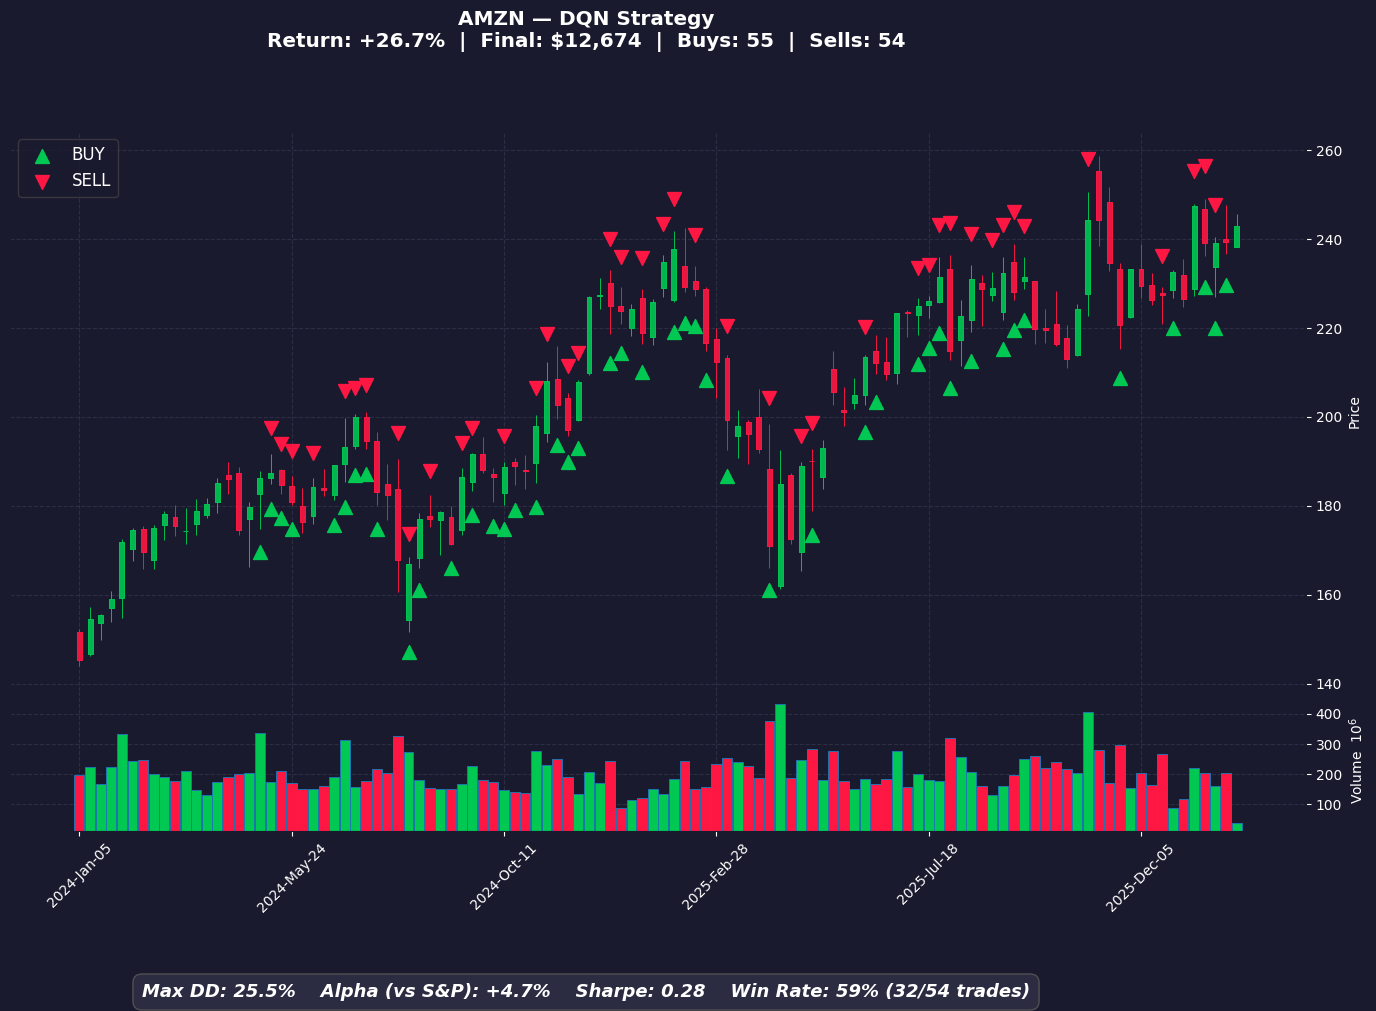

### AMZN — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-05-01,BUY,$179.00,55,"$9,845.00","$9,990.16"
2024-05-07,SELL,$188.76,55,"$10,381.80","$10,516.57"
2024-05-09,BUY,$189.50,55,"$10,422.50","$10,506.15"
2024-05-10,SELL,$187.48,55,"$10,311.40","$10,384.74"
2024-05-13,BUY,$186.57,55,"$10,261.35","$10,374.48"
2024-05-14,SELL,$187.07,55,"$10,288.85","$10,391.69"
2024-05-15,BUY,$185.99,55,"$10,229.45","$10,381.46"
2024-05-17,SELL,$184.70,55,"$10,158.50","$10,300.35"
2024-05-21,BUY,$183.15,56,"$10,256.40","$10,290.09"
2024-05-22,SELL,$183.13,56,"$10,255.28","$10,278.72"


In [4]:
plot_ticker('AMZN', method='DQN')

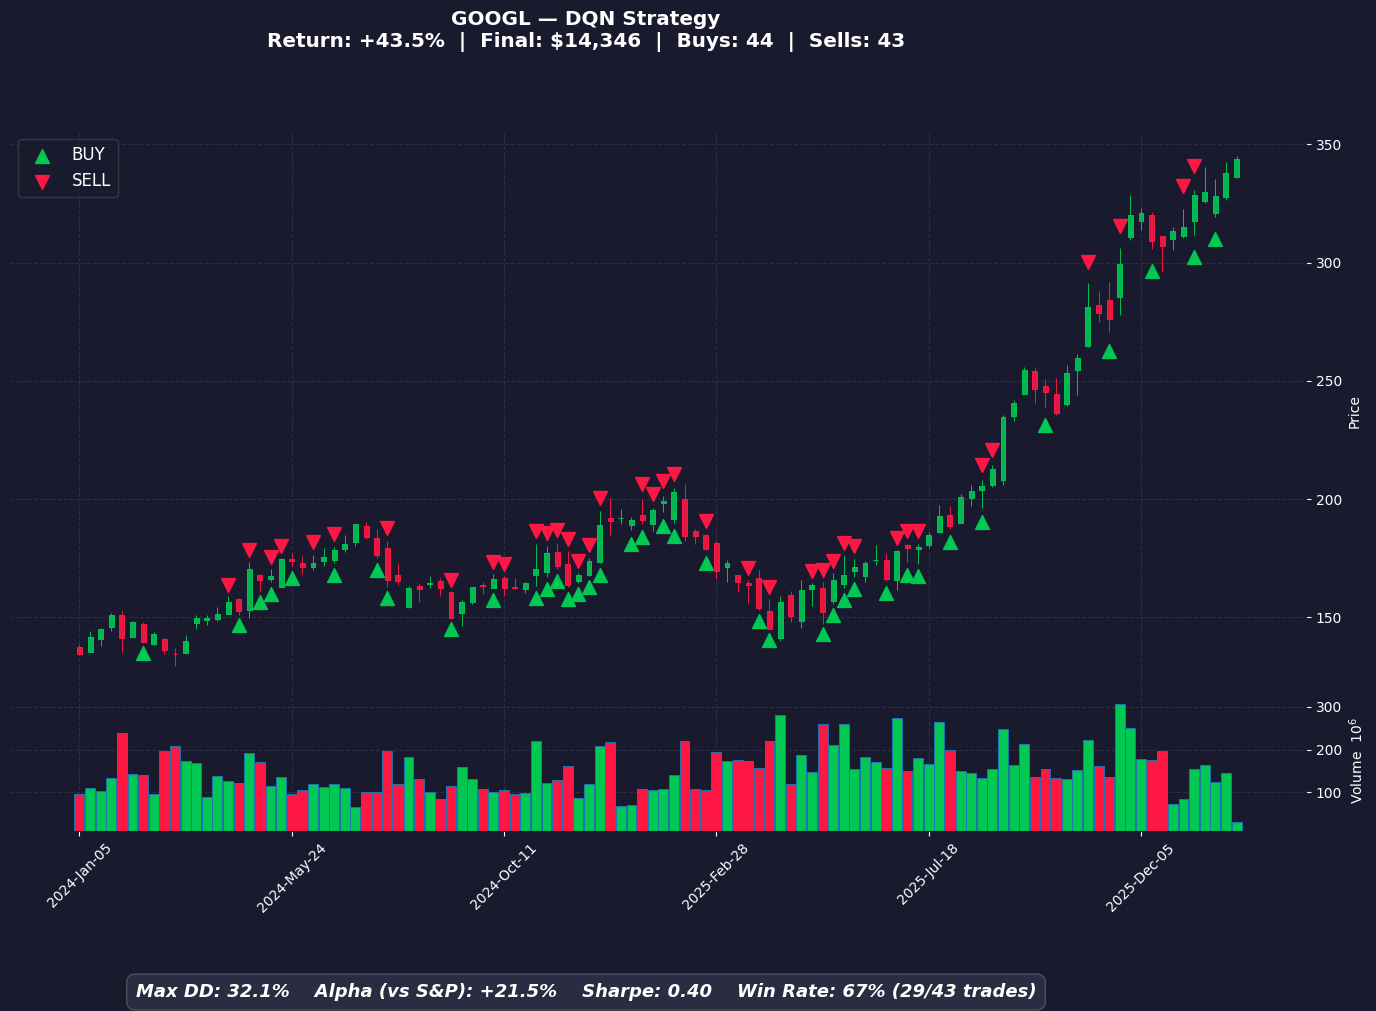

### GOOGL — Trade Log (DQN)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$144.84,68,"$9,848.89","$9,990.15"
2024-04-09,SELL,$155.42,68,"$10,568.29","$10,698.98"
2024-04-16,BUY,$153.23,69,"$10,573.06","$10,688.41"
2024-04-26,SELL,$170.65,69,"$11,774.85","$11,878.43"
2024-04-30,BUY,$161.55,73,"$11,793.10","$11,866.64"
2024-05-08,SELL,$168.10,73,"$12,271.26","$12,332.52"
2024-05-09,BUY,$168.68,73,"$12,313.28","$12,320.21"
2024-05-20,SELL,$175.58,73,"$12,817.52","$12,811.63"
2024-05-24,BUY,$173.67,73,"$12,677.69","$12,798.95"
2024-06-10,SELL,$173.89,73,"$12,693.63","$12,802.20"


In [5]:
plot_ticker('GOOGL', method='DQN')

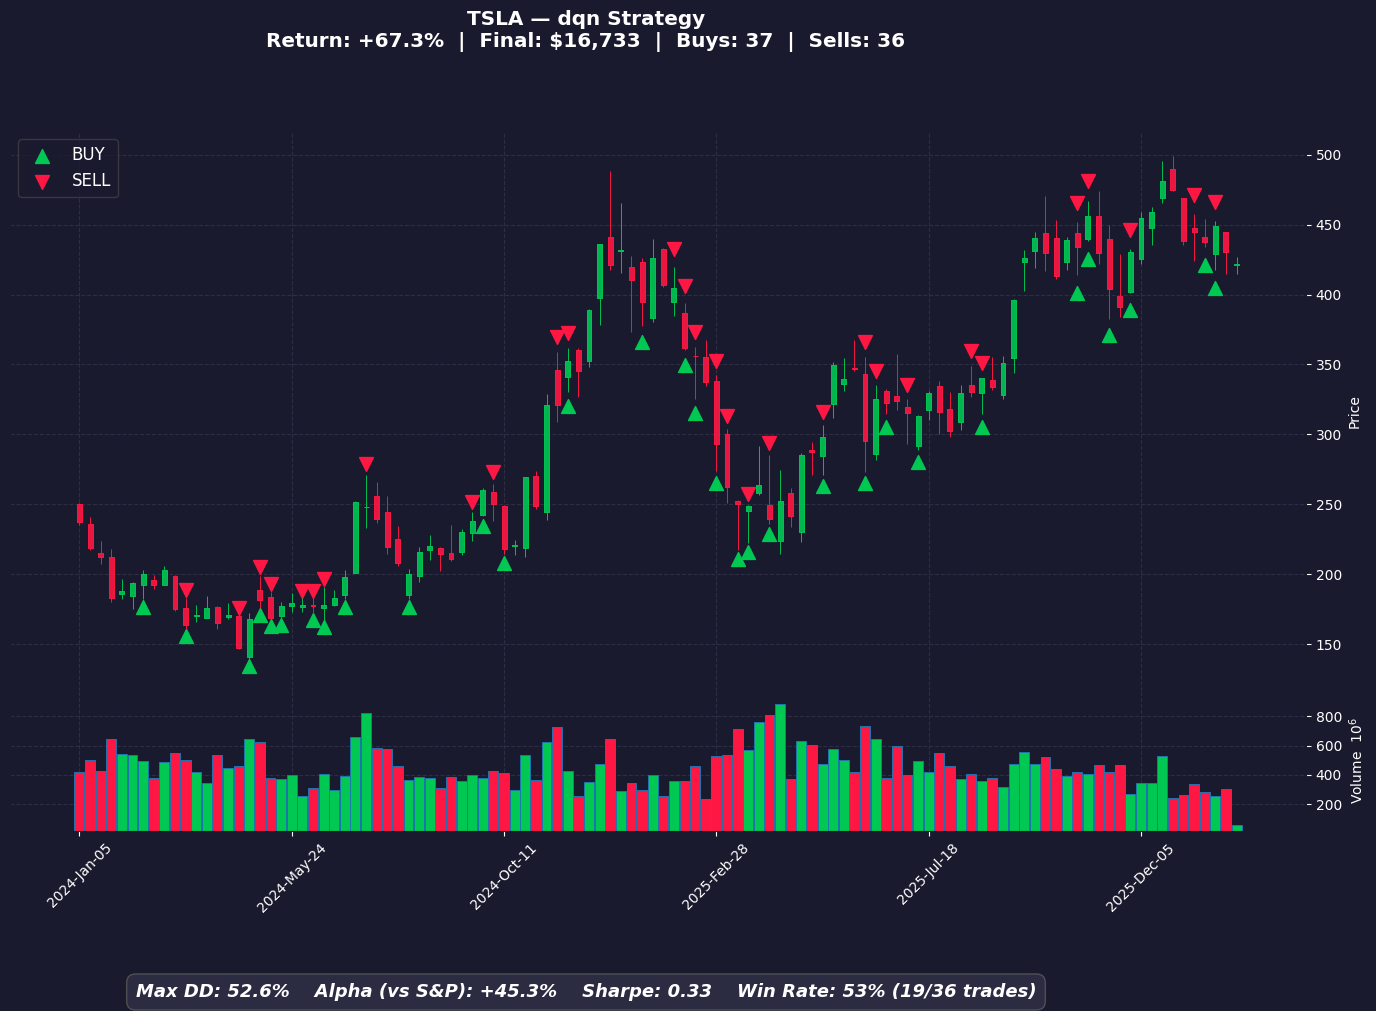

### TSLA — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$188.71,52,"$9,812.92","$9,990.19"
2024-03-13,SELL,$169.48,52,"$8,812.96","$8,981.41"
2024-03-14,BUY,$162.50,55,"$8,937.50","$8,972.48"
2024-04-22,SELL,$142.05,55,"$7,812.75","$7,839.91"
2024-04-23,BUY,$144.68,54,"$7,812.72","$7,832.10"
2024-05-02,SELL,$180.01,54,"$9,720.54","$9,730.20"
2024-05-03,BUY,$181.19,53,"$9,603.07","$9,720.60"
2024-05-06,SELL,$184.76,53,"$9,792.28","$9,900.02"
2024-05-07,BUY,$177.81,55,"$9,779.55","$9,890.24"
2024-05-08,SELL,$174.72,55,"$9,609.60","$9,710.68"


In [6]:
plot_ticker('TSLA', method='dqn')

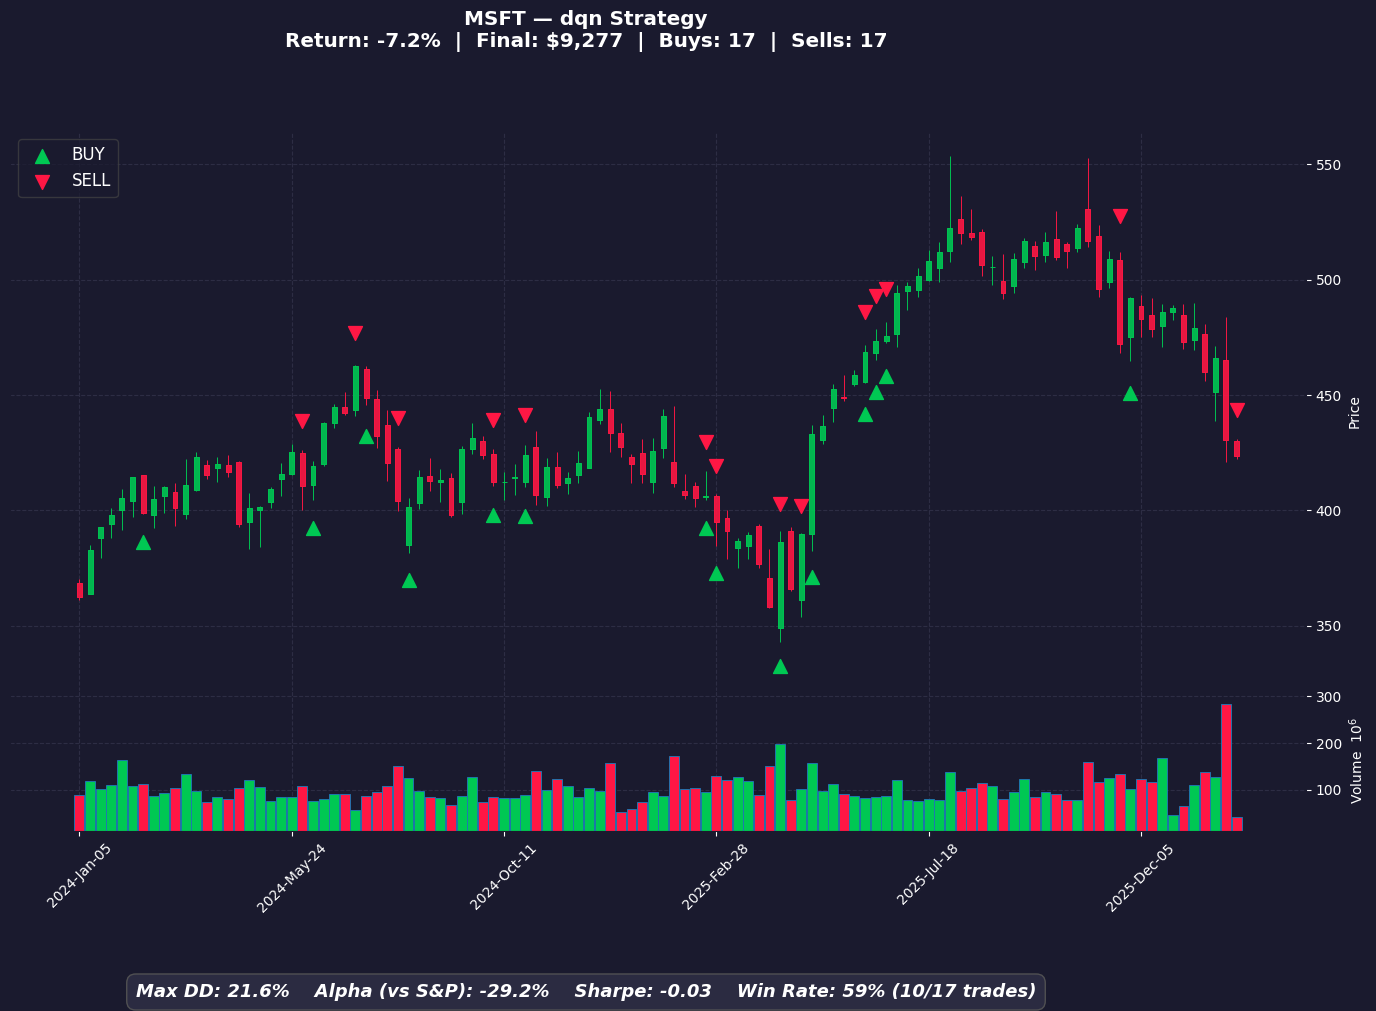

### MSFT — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$404.23,24,"$9,701.54","$9,990.30"
2024-06-03,SELL,$408.93,24,"$9,814.38","$10,093.33"
2024-06-04,BUY,$411.45,24,"$9,874.90","$10,083.45"
2024-07-03,SELL,$455.66,24,"$10,935.80","$11,133.42"
2024-07-12,BUY,$448.52,24,"$10,764.44","$11,122.65"
2024-08-05,SELL,$390.77,24,"$9,378.39","$9,727.22"
2024-08-06,BUY,$395.18,24,"$9,484.25","$9,717.74"
2024-10-02,SELL,$413.24,24,"$9,917.70","$10,141.27"
2024-10-03,BUY,$412.65,24,"$9,903.67","$10,131.37"
2024-10-24,SELL,$420.77,24,"$10,098.39","$10,316.00"


In [7]:
plot_ticker('MSFT', method='dqn')

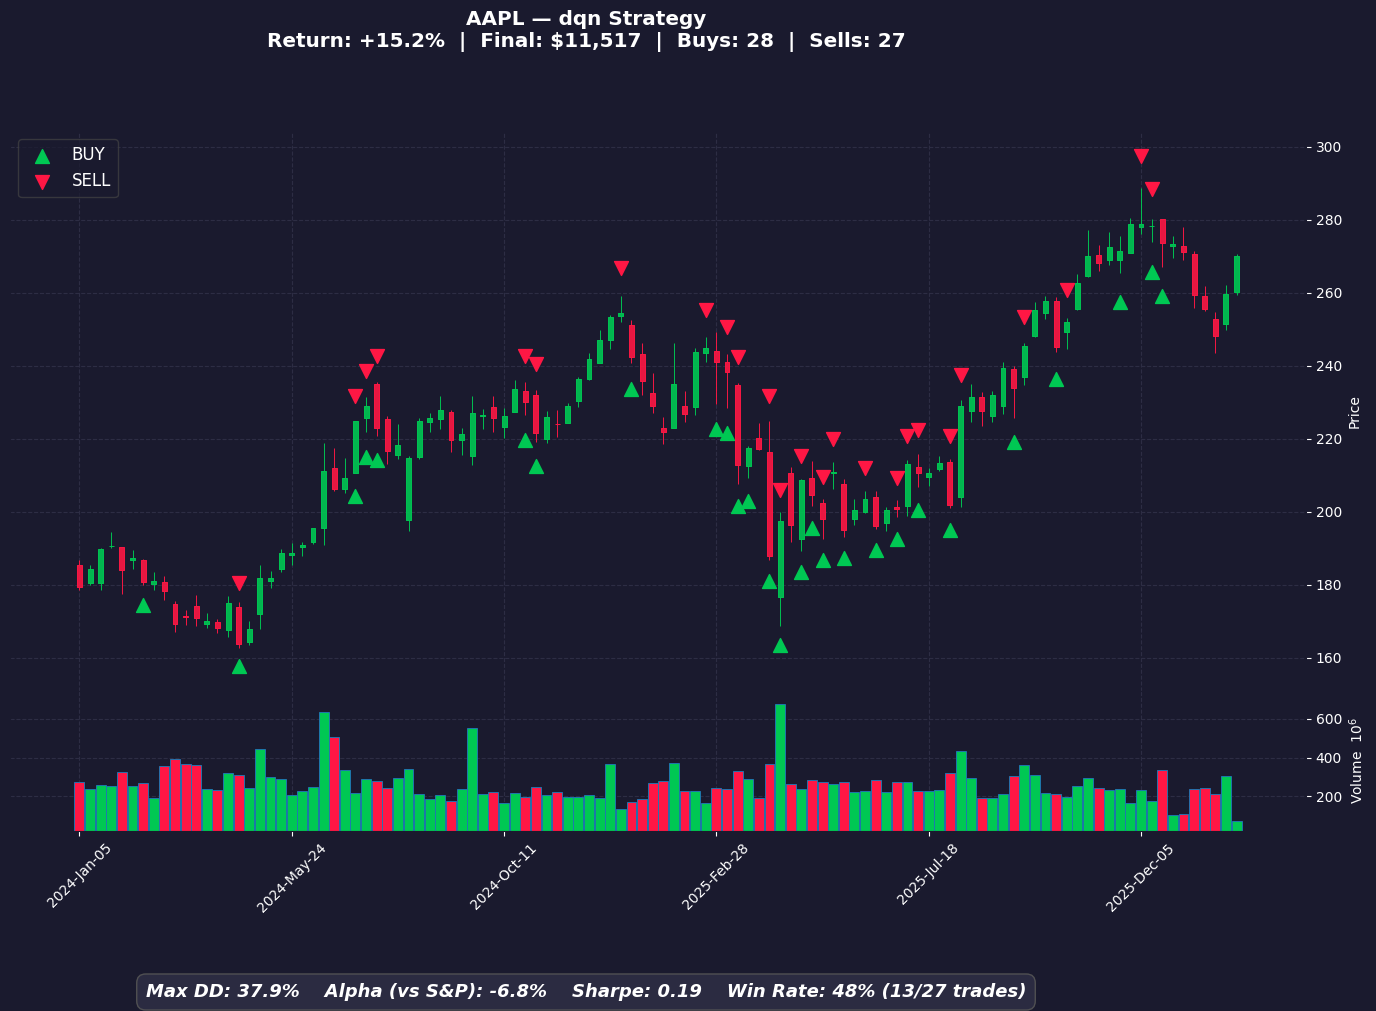

### AAPL — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-14,BUY,$182.67,54,"$9,864.34","$9,990.14"
2024-04-19,SELL,$163.68,54,"$8,838.54","$8,955.49"
2024-04-22,BUY,$164.51,54,"$8,883.53","$8,946.61"
2024-07-02,SELL,$218.80,54,"$11,815.29","$11,866.55"
2024-07-03,BUY,$220.07,53,"$11,663.88","$11,854.89"
2024-07-12,SELL,$229.00,53,"$12,137.17","$12,316.05"
2024-07-15,BUY,$232.84,52,"$12,107.55","$12,303.94"
2024-07-16,SELL,$233.25,52,"$12,129.25","$12,313.50"
2024-07-17,BUY,$227.35,54,"$12,277.13","$12,301.23"
2024-10-22,SELL,$234.56,54,"$12,666.08","$12,677.51"


In [8]:
plot_ticker('AAPL', method='dqn')

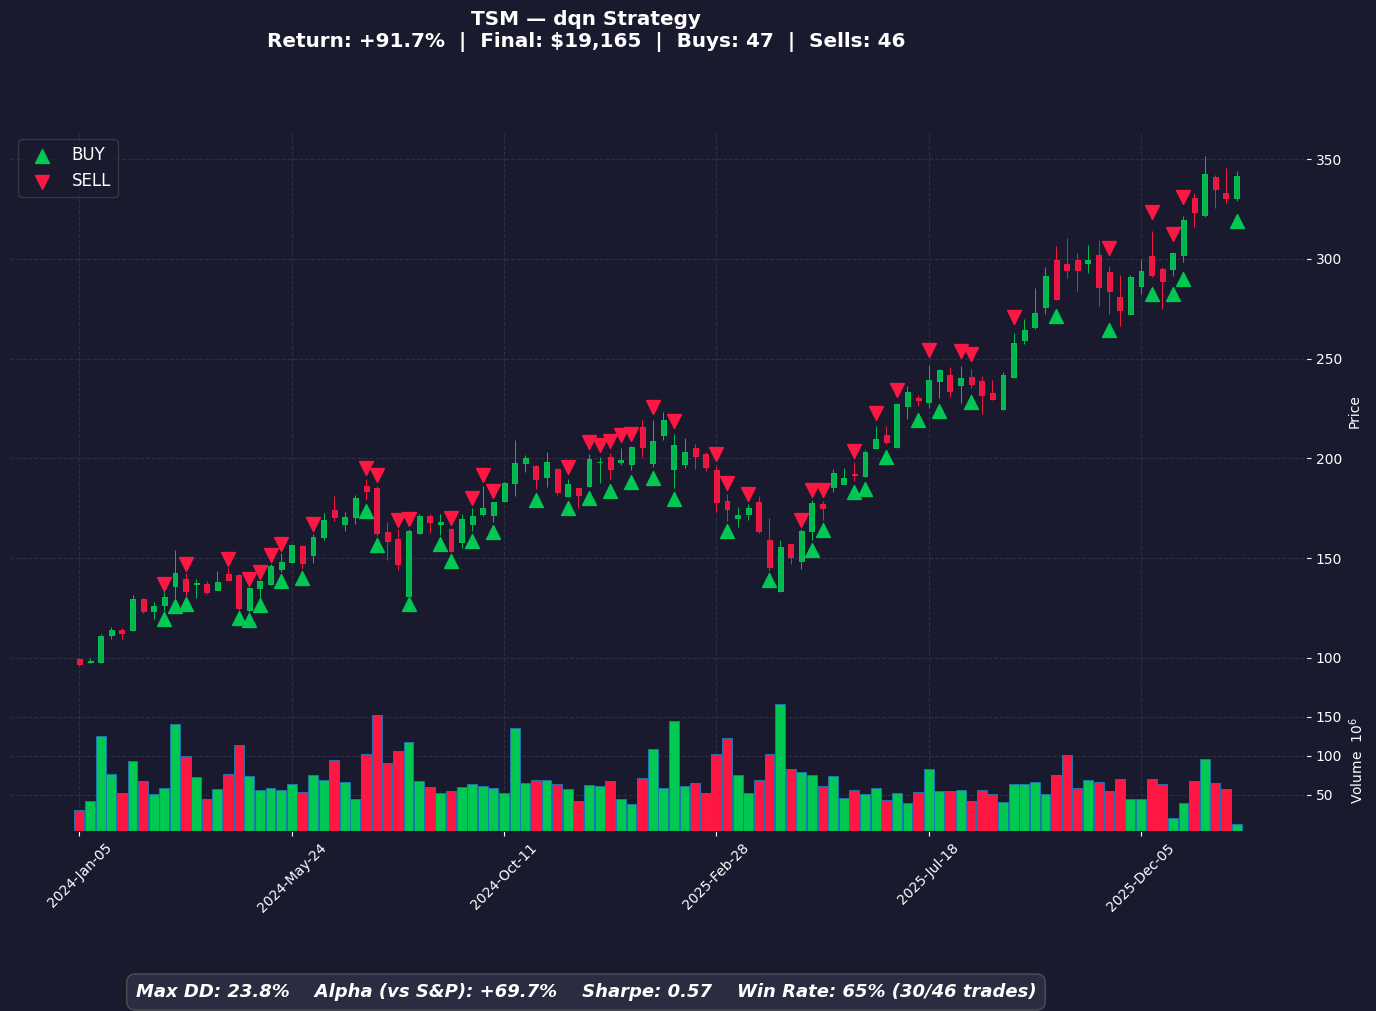

### TSM — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-03-01,BUY,$130.31,76,"$9,903.46","$9,990.10"
2024-03-04,SELL,$134.55,76,"$10,225.93","$10,302.34"
2024-03-08,BUY,$142.44,72,"$10,255.98","$10,292.09"
2024-03-12,SELL,$140.53,72,"$10,117.95","$10,143.93"
2024-03-14,BUY,$135.88,74,"$10,054.77","$10,133.88"
2024-04-09,SELL,$142.07,74,"$10,513.44","$10,582.03"
2024-04-17,BUY,$135.85,77,"$10,460.39","$10,571.57"
2024-04-25,SELL,$133.46,77,"$10,276.06","$10,376.96"
2024-04-29,BUY,$135.33,76,"$10,285.18","$10,366.68"
2024-04-30,SELL,$134.20,76,"$10,199.04","$10,270.34"


In [9]:
plot_ticker('TSM', method='dqn')

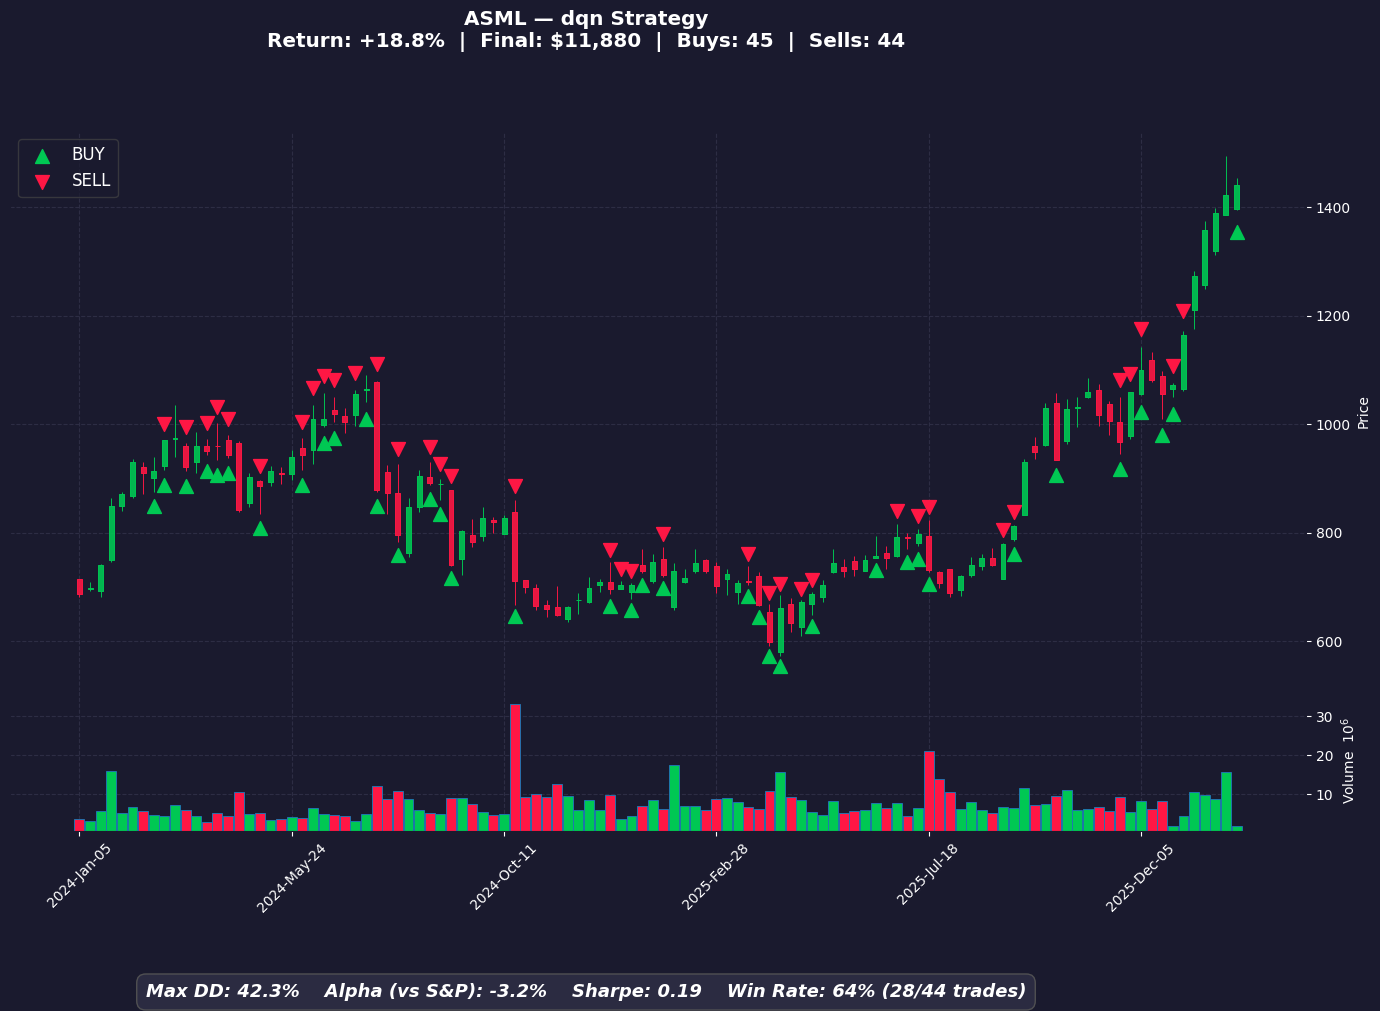

### ASML — Trade Log (dqn)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_25577/3758336801.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-23,BUY,$914.83,10,"$9,148.29","$9,990.85"
2024-02-28,SELL,$920.96,10,"$9,209.56","$10,042.91"
2024-02-29,BUY,$932.90,10,"$9,328.96","$10,033.58"
2024-03-13,SELL,$949.66,10,"$9,496.58","$10,191.71"
2024-03-15,BUY,$921.65,11,"$10,138.17","$10,181.57"
2024-03-25,SELL,$959.61,11,"$10,555.69","$10,588.53"
2024-03-26,BUY,$952.13,11,"$10,473.41","$10,578.05"
2024-03-27,SELL,$954.78,11,"$10,502.63","$10,596.77"
2024-03-28,BUY,$951.31,11,"$10,464.46","$10,586.31"
2024-04-03,SELL,$960.92,11,"$10,570.13","$10,681.41"


In [10]:
plot_ticker('ASML', method='dqn')